# 09 · Real-Data Validation Track — do our methods hold on REAL credit data?
**Project:** IntelliCredit — FinTech Micro-Lending Risk & Alternative Credit Scoring Engine
**Responds to the Review 1 panel comment:** *"Why synthetic data? Use real data."*

Borrower-level credit files in India cannot legally be shared with students: credit information is protected by the
**Credit Information Companies (Regulation) Act, 2005** and personal data by the **Digital Personal Data Protection Act, 2023**.
So instead of pretending, we did two things:

1. **Collected every real credit-risk dataset that is legally open**, from official statistical APIs (`src/real_data.py`), with raw responses cached and provenance logged in `data/real/real_sources.json`.
2. **Re-ran both Unit 3 methods on that real data**, and used it to **audit the synthetic data** — where the simulation agrees with reality, and where it does not.

| # | Real dataset (API) | Level | Size | Used in |
|---|---|---|---|---|
| 1 | IMF Financial Soundness Indicators — **India banks' NPL ratio** | quarterly, 2010-Q1 → latest | 63 quarters | Part B — Method 1 on real Indian defaults |
| 2 | World Bank WDI — NPL ratio + GDP, unemployment, inflation, lending rate | country-year, 2000 → 2025 | ~150 countries | Part C — is our macro → default mechanism real? |
| 3 | FRED — US consumer-loan delinquency + unemployment | quarterly, 1987 → latest | ~158 quarters | Part B2 — conformal intervals on a long real series |
| 4 | CFPB **HMDA** — loan-level applications with the lender's decision | one row per application, 2023 | ~48,800 loans | Part D — Method 2 on real loan records + fairness |
| 5 | CFPB Consumer Complaint Database — payday / personal loans | one row per complaint | 15,000 | Part E — what borrowers actually complain about |

**Innovation used throughout:** *conformal prediction* — distribution-free prediction intervals with a coverage guarantee
(Vovk et al. 2005; Angelopoulos & Bates 2021), including **Adaptive Conformal Inference** (Gibbs & Candès 2021), which keeps
its coverage even when the data shift (COVID, regulatory changes).

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings('ignore')
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)
REAL = os.path.join(ROOT, 'data', 'real')
FIG = os.path.join(ROOT, 'reports', 'figures', 'real')
OUT = os.path.join(ROOT, 'models', 'real')
os.makedirs(FIG, exist_ok=True); os.makedirs(OUT, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight'})
RESULTS = {}   # every headline number is stored here and saved to models/real/real_data_results.json

## Part A — Provenance and quality of the real data
Every file comes from `python -m src.real_data`. The table below is read from the provenance log, not typed by hand.

In [2]:
with open(os.path.join(REAL, 'real_sources.json'), encoding='utf-8') as f:
    src = json.load(f)
prov = pd.DataFrame([{ 'dataset': k, 'rows': v.get('rows'), 'endpoint': v.get('endpoint'),
                       'fetched (UTC)': v.get('fetched_at'), 'licence': v.get('licence')} for k, v in src.items()])
prov

,dataset,rows,endpoint,fetched (UTC),licence
0,imf_india_npl,63,https://api.imf.org/external/sdmx/2.1/data/IMF...,2026-11-06T13:43:06+00:00,"IMF data, CC BY 4.0 (imf.org/en/About/copyrigh..."
1,world_bank_panel,5642,https://api.worldbank.org/v2/country/all/indic...,2026-11-06T13:43:06+00:00,"World Bank Open Data, CC BY 4.0"
2,fred_us_consumer_credit,158,https://fred.stlouisfed.org/graph/fredgraph.cs...,2026-11-06T13:43:06+00:00,FRED; Federal Reserve Board charge-off & delin...
3,hmda_applications,48799,https://ffiec.cfpb.gov/v2/data-browser-api/vie...,2026-11-06T13:43:08+00:00,US federal government open data (ffiec.cfpb.go...
4,cfpb_complaints,15000,https://www.consumerfinance.gov/data-research/...,2026-11-06T13:43:09+00:00,US federal government open data (consumerfinan...


In [3]:
npl = pd.read_csv(os.path.join(REAL, 'india_bank_npl_quarterly.csv'), parse_dates=['quarter_start'], index_col='quarter_start')
wb  = pd.read_csv(os.path.join(REAL, 'world_bank_npl_panel.csv'))
us  = pd.read_csv(os.path.join(REAL, 'us_consumer_credit_quarterly.csv'), parse_dates=['quarter_start'], index_col='quarter_start')
hm  = pd.read_csv(os.path.join(REAL, 'hmda_applications_2023.csv'), low_memory=False)
cf  = pd.read_csv(os.path.join(REAL, 'cfpb_loan_complaints.csv'), parse_dates=['date_received'])

full_q = pd.date_range(npl.index.min(), npl.index.max(), freq='QS')
missing_q = [str(d.date()) for d in full_q.difference(npl.index)]
quality = pd.DataFrame({
    'rows': [len(npl), len(wb), len(us), len(hm), len(cf)],
    'columns': [npl.shape[1], wb.shape[1], us.shape[1], hm.shape[1], cf.shape[1]],
    'missing cells %': [round(100 * d.isna().mean().mean(), 1) for d in (npl, wb, us, hm, cf)],
    'duplicate rows': [int(npl.index.duplicated().sum()), int(wb.duplicated(['iso3', 'year']).sum()),
                       int(us.index.duplicated().sum()), int(hm.duplicated().sum()), int(cf.complaint_id.duplicated().sum())],
}, index=['IMF India NPL (quarterly)', 'World Bank panel', 'FRED US consumer credit', 'HMDA applications', 'CFPB complaints'])
print('IMF India series: missing quarters ->', missing_q, '(filled by linear interpolation of the log ratio)')
RESULTS['india_missing_quarters'] = missing_q
quality

IMF India series: missing quarters -> ['2010-04-01', '2010-10-01', '2011-04-01'] (filled by linear interpolation of the log ratio)


,rows,columns,missing cells %,duplicate rows
IMF India NPL (quarterly),63,2,0.0,0
World Bank panel,5642,10,16.5,0
FRED US consumer credit,158,6,1.7,0
HMDA applications,48799,31,10.7,33
CFPB complaints,15000,10,9.0,0


## Part B — Method 1 on REAL Indian defaults: forecasting the banking-system NPL ratio
**Question:** can the same time-series approach we used on the simulated portfolio forecast the *real* NPL ratio of Indian banks?

The real series has a story the simulation never had:
* **2015-Q3 → 2018-Q1 — RBI Asset Quality Review (AQR):** RBI forced banks to *recognise* hidden bad loans, so NPLs jumped from ~4% to ~11%. This is a **regulatory recognition shock**, not an economic one.
* **2018-Q2 onward — resolution / clean-up regime:** the Insolvency and Bankruptcy Code (2016), recoveries, write-offs and recapitalisation pull the ratio down year after year.
* **2020 — COVID moratorium (Mar–Aug 2020) and the Supreme Court standstill on NPA classification (Sep 2020 – Mar 2021):** defaults were *not allowed to be recognised*, so the NPL ratio did **not** spike in COVID — the opposite of our simulation.

These regimes come from the public record (as the COVID dummies did in notebook 06). Because the model works on the
*change* in log NPL (d = 1), each regime enters as a **ramp** (a running count of quarters in the regime): its coefficient is the
extra quarterly growth of the NPL ratio while the regime is active.

macro history available to: {'cpi_inflation_yoy': '2026-07-01', 'call_money_rate': '2026-07-01', 'unemployment_rate': '2026-07-01', 'gdp_growth': '2026-07-01'}
exogenous columns: ['aqr_recognition_ramp', 'resolution_regime_ramp', 'covid_standstill_ramp', 'cpi_inflation_yoy_l1', 'call_money_rate_l1', 'unemployment_rate_l1', 'gdp_growth_l1', 'cpi_inflation_yoy_l2', 'call_money_rate_l2', 'unemployment_rate_l2', 'gdp_growth_l2']


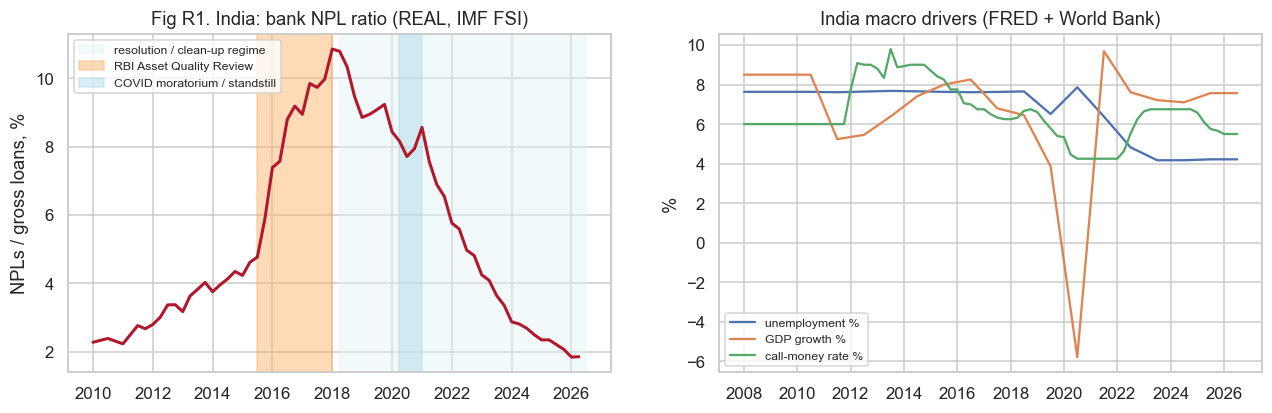

In [4]:
y_npl = np.log(npl['npl_ratio_pct'].reindex(full_q).interpolate())
y_npl.index.freq = 'QS'

# India macro, quarterly, from the SAME FRED / World Bank raw caches used by src/macro_api.py
RAWX = os.path.join(ROOT, 'data', 'external', 'raw')
def fred_q(sid):
    s = pd.read_csv(os.path.join(RAWX, f'fred_{sid}.csv'), parse_dates=[0], index_col=0, na_values='.').iloc[:, 0]
    return s.resample('QS').mean()
def wb_q(ind):
    rows = json.load(open(os.path.join(RAWX, f'worldbank_{ind}.json'), encoding='utf-8'))
    rows = rows[1] if isinstance(rows, list) and len(rows) == 2 and isinstance(rows[1], list) else rows
    a = pd.Series({pd.Timestamp(f"{r['date']}-07-01"): r['value'] for r in rows if r.get('value') is not None}).sort_index()
    return a.resample('QS').interpolate()
mq = pd.DataFrame({
    'cpi_inflation_yoy': fred_q('CPALTT01INM659N'),
    'call_money_rate': fred_q('IRSTCI01INM156N'),
    'unemployment_rate': wb_q('SL.UEM.TOTL.ZS'),
    'gdp_growth': wb_q('NY.GDP.MKTP.KD.ZG'),
}).loc['2008':]
mq = mq.ffill().bfill()   # CPI (OECD) stops in 2025-03, World Bank annual values run 2010-2025: carry the edges, flagged below
carried = {c: str(mq[c].last_valid_index().date()) for c in mq}

ev = pd.DataFrame(index=full_q)
ev['aqr_recognition'] = ((ev.index >= '2015-07-01') & (ev.index <= '2018-01-01')).astype(float)
ev['resolution_regime'] = (ev.index >= '2018-04-01').astype(float)
ev['covid_standstill'] = ((ev.index >= '2020-04-01') & (ev.index <= '2021-01-01')).astype(float)
REGIMES = [c + '_ramp' for c in ev.columns]
LAGS = [1, 2]   # quarters: macro conditions show up in recognised NPLs with a lag
X_all = pd.concat([ev.cumsum().add_suffix('_ramp')] + [mq.shift(L).reindex(full_q).add_suffix(f'_l{L}') for L in LAGS], axis=1)
print('macro history available to:', carried)
print('exogenous columns:', list(X_all.columns))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(npl.index, npl['npl_ratio_pct'], color='#b2182b', lw=2)
for a, b, lab, c in [('2018-04-01', '2026-06-30', 'resolution / clean-up regime', '#e0f3f8'), ('2015-07-01', '2018-01-01', 'RBI Asset Quality Review', '#fdae61'), ('2020-04-01', '2021-01-01', 'COVID moratorium / standstill', '#abd9e9')]:
    ax[0].axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, alpha=.45, label=lab)
ax[0].set(title='Fig R1. India: bank NPL ratio (REAL, IMF FSI)', ylabel='NPLs / gross loans, %'); ax[0].legend(fontsize=8)
ax[1].plot(mq.index, mq['unemployment_rate'], label='unemployment %'); ax[1].plot(mq.index, mq['gdp_growth'], label='GDP growth %')
ax[1].plot(mq.index, mq['call_money_rate'], label='call-money rate %'); ax[1].legend(fontsize=8)
ax[1].set(title='India macro drivers (FRED + World Bank)', ylabel='%')
plt.savefig(os.path.join(FIG, 'R1_india_npl_history.png')); plt.show()

### B1. Chronological split and competing models
Train **2010-Q1 → 2022-Q4** (52 quarters), test the **14 unseen quarters 2023-Q1 → 2026-Q2** in one multi-step forecast.
Five models, from naive to macro-driven; the SARIMAX order and driver set are chosen by **BIC on the training data only**.

In [5]:
TEST_START = '2023-01-01'
y_tr, y_te = y_npl[:'2022-10-01'], y_npl[TEST_START:]
X_tr, X_te = X_all.loc[y_tr.index], X_all.loc[y_te.index]
h = len(y_te)

def metrics(actual_pct, fc_pct, train_pct):
    e = fc_pct - actual_pct
    scale = np.mean(np.abs(np.diff(train_pct)))           # naive in-sample MAE (non-seasonal, quarterly)
    return {'MAE (pp)': np.mean(np.abs(e)), 'RMSE (pp)': np.sqrt(np.mean(e**2)),
            'MAPE %': 100 * np.mean(np.abs(e) / actual_pct), 'MASE': np.mean(np.abs(e)) / scale, 'Bias (pp)': np.mean(e)}

fc = {}
fc['Naive (last value)'] = pd.Series(np.exp(y_tr.iloc[-1]), index=y_te.index)
drift = (y_tr.iloc[-1] - y_tr.iloc[0]) / (len(y_tr) - 1)
fc['Drift'] = pd.Series(np.exp(y_tr.iloc[-1] + drift * np.arange(1, h + 1)), index=y_te.index)
ets = ExponentialSmoothing(y_tr, trend='add', damped_trend=True).fit()
fc['Holt damped trend (ETS)'] = np.exp(ets.forecast(h))

grid = []
for p in range(3):
    for q in range(3):
        try:
            m = SARIMAX(y_tr, order=(p, 1, q)).fit(disp=False)
            grid.append(((p, 1, q), m.bic))
        except Exception:
            pass
best_order = min(grid, key=lambda t: t[1])[0]
fc[f'ARIMA{best_order}'] = np.exp(SARIMAX(y_tr, order=best_order).fit(disp=False).forecast(h))

MACRO4 = ['unemployment_rate', 'gdp_growth', 'cpi_inflation_yoy', 'call_money_rate']
driver_sets = {'macro only (lag 2)': [f'{c}_l2' for c in MACRO4], 'regimes only': REGIMES}
for L in LAGS:
    driver_sets[f'regimes + unemployment + GDP (lag {L})'] = REGIMES + [f'unemployment_rate_l{L}', f'gdp_growth_l{L}']
    driver_sets[f'regimes + all four macro (lag {L})'] = REGIMES + [f'{c}_l{L}' for c in MACRO4]
sel = []
for name, cols in driver_sets.items():
    for order in [(1, 1, 0), (0, 1, 1), (1, 1, 1)]:
        m = SARIMAX(y_tr, exog=X_tr[cols], order=order).fit(disp=False)
        f = np.exp(m.forecast(h, exog=X_te[cols]))
        sel.append({'driver set': name, 'order': order, 'BIC': round(m.bic, 2), 'AIC': round(m.aic, 2),
                    'test MAE (pp), shown not used': round(float(np.mean(np.abs(f - np.exp(y_te)))), 3), 'cols': cols})
sel = pd.DataFrame(sel).sort_values('BIC')
best = sel.iloc[0]
RESULTS['india_spec_table'] = sel.drop(columns='cols').astype(str).to_dict(orient='records')
sx = SARIMAX(y_tr, exog=X_tr[best['cols']], order=best['order']).fit(disp=False)
fc['SARIMAX (BIC choice)'] = np.exp(sx.forecast(h, exog=X_te[best['cols']]))
print(f"ARIMA order by BIC: {best_order} | SARIMAX choice: {best['driver set']} {best['order']}")
display(sel.drop(columns='cols').groupby('driver set').head(1))

actual = np.exp(y_te); train_pct = np.exp(y_tr)
cmp_india = pd.DataFrame({k: metrics(actual.values, v.values, train_pct.values) for k, v in fc.items()}).T.sort_values('MAE (pp)')
cmp_india.round(3).to_csv(os.path.join(OUT, 'india_npl_model_comparison.csv'))
RESULTS['india_best_model'] = cmp_india.index[0]
RESULTS['india_model_comparison'] = cmp_india.round(4).to_dict(orient='index')
cmp_india.round(3)

ARIMA order by BIC: (1, 1, 1) | SARIMAX choice: regimes only (0, 1, 1)


,driver set,order,BIC,AIC,"test MAE (pp), shown not used"
4,regimes only,"(0, 1, 1)",-114.55,-124.21,0.482
13,regimes + unemployment + GDP (lag 2),"(0, 1, 1)",-109.49,-123.01,0.735
6,regimes + unemployment + GDP (lag 1),"(1, 1, 0)",-107.36,-120.88,0.303
9,regimes + all four macro (lag 1),"(1, 1, 0)",-104.52,-121.91,0.256
0,macro only (lag 2),"(1, 1, 0)",-103.18,-114.77,1.790
16,regimes + all four macro (lag 2),"(0, 1, 1)",-101.93,-119.32,0.801


,MAE (pp),RMSE (pp),MAPE %,MASE,Bias (pp)
SARIMAX (BIC choice),0.482,0.501,18.757,1.262,0.482
Holt damped trend (ETS),0.913,0.961,37.930,2.391,0.913
"ARIMA(1, 1, 1)",1.030,1.092,43.104,2.698,1.030
Naive (last value),2.036,2.172,85.684,5.332,2.036
Drift,2.606,2.815,110.734,6.824,2.606


In [6]:
print(sx.summary().tables[1])
coef = sx.params.drop([c for c in sx.params.index if c.startswith(('ar.', 'ma.', 'sigma'))])
eff = pd.DataFrame({'beta': coef.round(4), 'p-value': sx.pvalues[coef.index].round(4),
                    'effect on NPL ratio': [f"{100*(np.exp(b)-1):+.1f}% per +1 unit" if not c.endswith('_ramp') else f"{100*(np.exp(b)-1):+.1f}% per quarter while active" for c, b in coef.items()]})
RESULTS['india_sarimax_choice'] = f"{best['driver set']} {best['order']}"
# robustness: the macro effects when all four drivers are forced in (lag 2)
rob_cols = driver_sets['regimes + all four macro (lag 2)']
sx_rob = SARIMAX(y_tr, exog=X_tr[rob_cols], order=best['order']).fit(disp=False)
RESULTS['india_sarimax_effects'] = eff.astype(str).to_dict(orient='index')
eff

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
aqr_recognition_ramp       0.0766      0.018      4.213      0.000       0.041       0.112
resolution_regime_ramp    -0.0556      0.024     -2.349      0.019      -0.102      -0.009
covid_standstill_ramp      0.0619      0.050      1.248      0.212      -0.035       0.159
ma.L1                      0.0687      0.131      0.523      0.601      -0.189       0.326
sigma2                     0.0042      0.001      3.780      0.000       0.002       0.006


,beta,p-value,effect on NPL ratio
aqr_recognition_ramp,0.0766,0.0000,+8.0% per quarter while active
resolution_regime_ramp,-0.0556,0.0188,-5.4% per quarter while active
covid_standstill_ramp,0.0619,0.2121,+6.4% per quarter while active


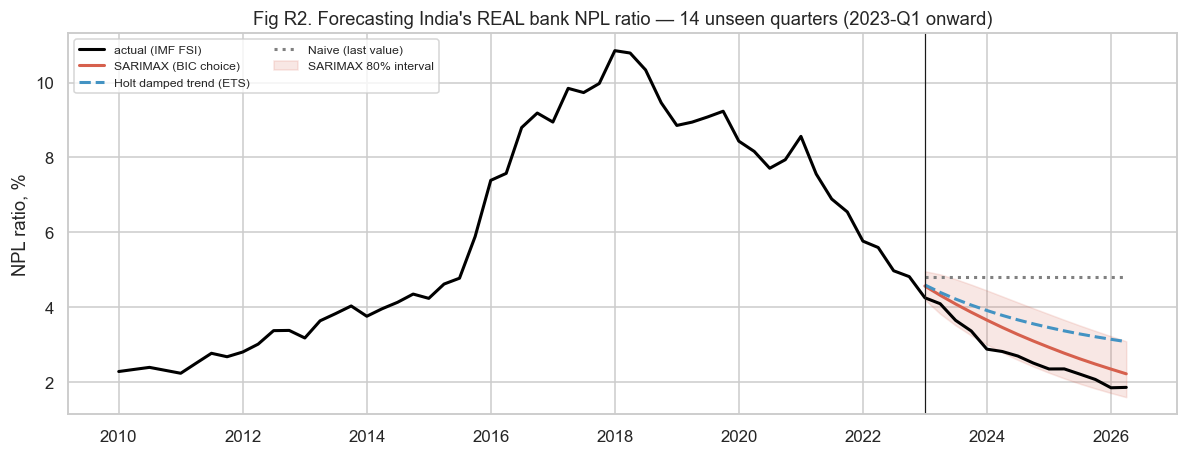

In [7]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(np.exp(y_npl).index, np.exp(y_npl), color='black', lw=2, label='actual (IMF FSI)')
styles = {'SARIMAX (BIC choice)': ('#d6604d', '-'), 'Holt damped trend (ETS)': ('#4393c3', '--'), 'Naive (last value)': ('grey', ':')}
for k, (c, ls) in styles.items():
    ax.plot(fc[k].index, fc[k], color=c, ls=ls, lw=2, label=k)
pi = sx.get_forecast(h, exog=X_te[best['cols']]).conf_int(alpha=0.2)
ax.fill_between(y_te.index, np.exp(pi.iloc[:, 0]), np.exp(pi.iloc[:, 1]), color='#d6604d', alpha=.15, label='SARIMAX 80% interval')
ax.axvline(pd.Timestamp(TEST_START), color='k', lw=.8)
ax.set(title='Fig R2. Forecasting India\'s REAL bank NPL ratio — 14 unseen quarters (2023-Q1 onward)', ylabel='NPL ratio, %')
ax.legend(fontsize=8, ncol=2)
plt.savefig(os.path.join(FIG, 'R2_india_npl_forecast.png')); plt.show()

### B2. Conformal prediction intervals — an honest uncertainty band (innovation)
Model-based (Gaussian) intervals assume the model is correct. **Conformal prediction** needs only that past forecast errors are
informative about future ones, and gives a finite-sample coverage guarantee under exchangeability.
For time series, where exchangeability fails, **Adaptive Conformal Inference (ACI)** updates the miscoverage level after every
observation: $\alpha_{t+1} = \alpha_t + \gamma(\alpha - \mathrm{err}_t)$ — widening the band after a miss and narrowing it after a hit,
which guarantees long-run coverage even under distribution shift (Gibbs & Candès 2021).

We run a **rolling one-step-ahead backtest** (refit each quarter) and compare the empirical coverage of three 80% / 90% intervals.

In [8]:
def rolling_one_step(y, X, cols, order, start):
    rows = []
    for t in y.index[y.index >= start]:
        yt, Xt = y[y.index < t], (X.loc[y.index[y.index < t], cols] if cols else None)
        m = SARIMAX(yt, exog=Xt, order=order).fit(disp=False)
        f = m.get_forecast(1, exog=(X.loc[[t], cols] if cols else None))
        mu, se = f.predicted_mean.iloc[0], np.sqrt(f.var_pred_mean.iloc[0])
        rows.append({'t': t, 'y': y[t], 'mu': mu, 'se': se})
    return pd.DataFrame(rows).set_index('t')

def conformal_coverage(bt, alpha, warmup=8, gamma=0.05):
    z = stats.norm.ppf(1 - alpha / 2)
    res = np.abs(bt['y'] - bt['mu']).values
    gauss = np.abs(bt['y'] - bt['mu']) <= z * bt['se']
    split, aci, widths_s, widths_a, a_t = [], [], [], [], alpha
    for i in range(warmup, len(bt)):
        past = res[:i]
        qs = np.quantile(past, min(1, np.ceil((i + 1) * (1 - alpha)) / i))          # split-conformal quantile
        qa = np.quantile(past, min(1, max(0, 1 - a_t))) if a_t > 0 else np.inf       # ACI quantile
        split.append(res[i] <= qs); widths_s.append(2 * qs)
        hit = res[i] <= qa; aci.append(hit); widths_a.append(2 * qa if np.isfinite(qa) else np.nan)
        a_t = a_t + gamma * (alpha - (0 if hit else 1))
    g = gauss.values[warmup:]
    return {'nominal': f'{100*(1-alpha):.0f}%', 'Gaussian model interval': np.mean(g), 'split conformal': np.mean(split),
            'adaptive conformal (ACI)': np.mean(aci), 'n forecasts': len(g),
            'mean width Gaussian (log pts)': float(np.mean(2 * z * bt['se'].values[warmup:])),
            'mean width ACI (log pts)': float(np.nanmean(widths_a))}

bt_india = rolling_one_step(y_npl, X_all, best['cols'], best['order'], start='2015-01-01')
cov_india = pd.DataFrame([conformal_coverage(bt_india, a) for a in (0.2, 0.1)]).set_index('nominal')
RESULTS['india_interval_coverage'] = cov_india.round(3).to_dict(orient='index')
cov_india.round(3)

,Gaussian model interval,split conformal,adaptive conformal (ACI),n forecasts,mean width Gaussian (log pts),mean width ACI (log pts)
nominal,,,,,,
80%,0.868,1.0,0.868,38,0.171,0.182
90%,0.974,1.0,0.947,38,0.220,0.234


### B3. The same test on a long real series — US consumer-loan delinquency (FRED, 1987 →)
India gives ~45 rolling forecasts; the US series gives ~100, enough to see the coverage behaviour through the 2008 crisis and COVID.
Model: SARIMAX on log delinquency with the unemployment rate (lag 1–2 quarters) — the standard driver in the credit-risk literature.

In [9]:
yu = np.log(us['consumer_loan_delinquency_pct']).asfreq('QS')
Xu = pd.DataFrame({'unemp_l1': us['unemployment_rate'].shift(1), 'd_unemp_l1': us['unemployment_rate'].diff().shift(1),
                   'fedfunds_l2': us['fed_funds_rate'].shift(2)}).reindex(yu.index)
ok = Xu.notna().all(axis=1); yu, Xu = yu[ok], Xu[ok]
bt_us = rolling_one_step(yu, Xu, list(Xu.columns), (1, 1, 0), start='2000-01-01')
cov_us = pd.DataFrame([conformal_coverage(bt_us, a, warmup=12) for a in (0.2, 0.1)]).set_index('nominal')
mae_us = float(np.mean(np.abs(np.exp(bt_us['y']) - np.exp(bt_us['mu']))))
naive_us = float(np.mean(np.abs(np.diff(np.exp(yu[yu.index >= '1999-10-01'])))))
RESULTS['us_interval_coverage'] = cov_us.round(3).to_dict(orient='index')
RESULTS['us_one_step_mae_pp'] = round(mae_us, 3); RESULTS['us_naive_mae_pp'] = round(naive_us, 3)
print(f'US one-step MAE {mae_us:.3f} pp vs naive {naive_us:.3f} pp over {len(bt_us)} quarters')
cov_us.round(3)

US one-step MAE 0.078 pp vs naive 0.097 pp over 106 quarters


,Gaussian model interval,split conformal,adaptive conformal (ACI),n forecasts,mean width Gaussian (log pts),mean width ACI (log pts)
nominal,,,,,,
80%,0.723,0.809,0.809,94,0.072,0.089
90%,0.830,0.904,0.904,94,0.093,0.139


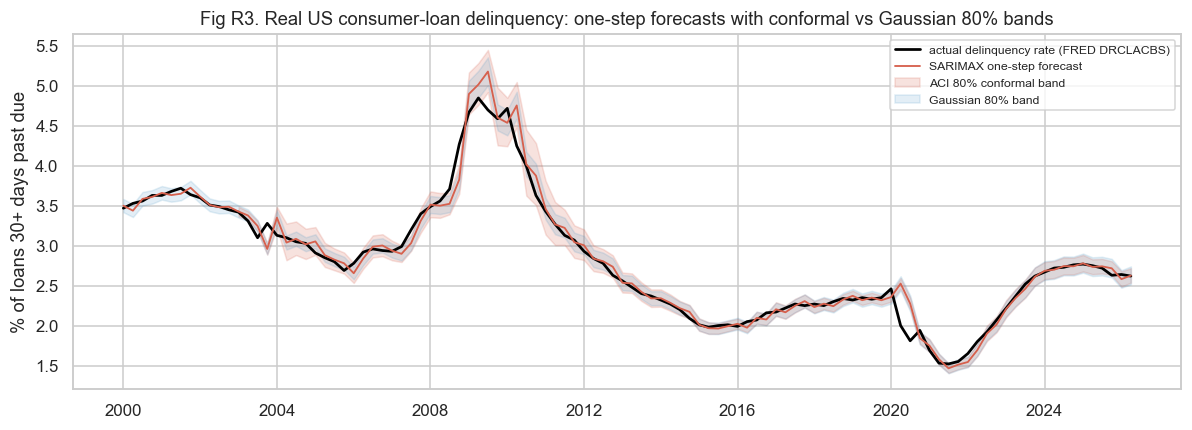

In [10]:
# Visualise the ACI band through time on the US series (80%)
alpha, gamma, warm = 0.2, 0.05, 12
res = np.abs(bt_us['y'] - bt_us['mu']).values
lo, hi, a_t, z = [], [], alpha, stats.norm.ppf(0.9)
for i in range(len(bt_us)):
    if i < warm:
        lo.append(np.nan); hi.append(np.nan); continue
    q = np.quantile(res[:i], min(1, max(0, 1 - a_t)))
    lo.append(bt_us['mu'].iloc[i] - q); hi.append(bt_us['mu'].iloc[i] + q)
    a_t += gamma * (alpha - (0 if res[i] <= q else 1))
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(bt_us.index, np.exp(bt_us['y']), color='black', lw=1.8, label='actual delinquency rate (FRED DRCLACBS)')
ax.plot(bt_us.index, np.exp(bt_us['mu']), color='#d6604d', lw=1.2, label='SARIMAX one-step forecast')
ax.fill_between(bt_us.index, np.exp(np.array(lo)), np.exp(np.array(hi)), color='#d6604d', alpha=.18, label='ACI 80% conformal band')
ax.fill_between(bt_us.index, np.exp(bt_us['mu'] - z * bt_us['se']), np.exp(bt_us['mu'] + z * bt_us['se']), color='#4393c3', alpha=.15, label='Gaussian 80% band')
ax.set(title='Fig R3. Real US consumer-loan delinquency: one-step forecasts with conformal vs Gaussian 80% bands', ylabel='% of loans 30+ days past due')
ax.legend(fontsize=8)
plt.savefig(os.path.join(FIG, 'R3_us_conformal_band.png')); plt.show()

## Part C — Is the macro → default mechanism in our simulation real? (World Bank panel, ~150 countries)
`src/portfolio_simulation.py` makes defaults rise with unemployment and fall with GDP growth, and notebook 06's SARIMAX recovered
those effects. If that mechanism were an artefact of our own assumptions, we would be learning from ourselves (circularity).
A **two-way fixed-effects panel regression** on real NPL data tests it independently:

$$\Delta \mathrm{NPL}_{it} = \mu_i + \tau_t + \beta_1 g_{it} + \beta_2 \Delta u_{it} + \beta_3 \pi_{it} + \beta_4 r_{it} + \varepsilon_{it}$$

(μ = country effect, τ = year effect, g = GDP growth, u = unemployment, π = inflation, r = lending rate; standard errors clustered by country — the specification family of Nkusu 2011 and Beck, Jakubik & Piloiu 2015.)

In [11]:
p = wb.sort_values(['iso3', 'year']).copy()
p['d_npl'] = p.groupby('iso3')['npl_ratio_pct'].diff()
p['d_unemp'] = p.groupby('iso3')['unemployment_rate'].diff()
p['inflation_w'] = p['inflation'].clip(-5, 50)          # winsorise hyper-inflation episodes
p['lending_rate_w'] = p['lending_rate'].clip(0, 60)
pp = p.dropna(subset=['d_npl', 'gdp_growth', 'd_unemp', 'inflation_w'])
pp = pp[pp['d_npl'].abs() < 20]                          # drop reporting breaks (|change| > 20 pp in one year)
fe = smf.ols('d_npl ~ gdp_growth + d_unemp + inflation_w + C(iso3) + C(year)', data=pp).fit(cov_type='cluster', cov_kwds={'groups': pp['iso3']})
pp2 = pp.dropna(subset=['lending_rate_w'])
fe2 = smf.ols('d_npl ~ gdp_growth + d_unemp + inflation_w + lending_rate_w + C(iso3) + C(year)', data=pp2).fit(cov_type='cluster', cov_kwds={'groups': pp2['iso3']})
panel_tab = pd.DataFrame({
    'β (no rate)': fe.params[['gdp_growth', 'd_unemp', 'inflation_w']],
    'p (no rate)': fe.pvalues[['gdp_growth', 'd_unemp', 'inflation_w']],
    'β (with lending rate)': fe2.params[['gdp_growth', 'd_unemp', 'inflation_w', 'lending_rate_w']],
    'p (with lending rate)': fe2.pvalues[['gdp_growth', 'd_unemp', 'inflation_w', 'lending_rate_w']],
}).round(4)
print(f"panel: {pp.iso3.nunique()} countries, {len(pp):,} country-years ({pp.year.min()}–{pp.year.max()}); with lending rate: {pp2.iso3.nunique()} countries, {len(pp2):,} obs")
RESULTS['panel'] = {'countries': int(pp.iso3.nunique()), 'obs': int(len(pp)), 'years': f'{pp.year.min()}-{pp.year.max()}',
                    'coefficients': panel_tab.astype(float).round(4).to_dict(orient='index')}
panel_tab

panel: 140 countries, 2,021 country-years (2002–2025); with lending rate: 101 countries, 1,310 obs


,β (no rate),p (no rate),β (with lending rate),p (with lending rate)
d_unemp,0.2798,0.0145,0.1391,0.1049
gdp_growth,-0.1107,0.0484,-0.0659,0.1678
inflation_w,0.0803,0.0022,0.0978,0.0057
lending_rate_w,NaN,NaN,0.0418,0.2409


In [12]:
# Sign-agreement scorecard: synthetic simulation (notebook 06 SARIMAX) vs real-data estimates
sim_effects = {'GDP growth': -0.0191, 'Unemployment': +0.1886, 'Inflation': +0.1428, 'Interest rate': +0.0987}
real_panel = {'GDP growth': fe.params['gdp_growth'], 'Unemployment': fe.params['d_unemp'],
              'Inflation': fe.params['inflation_w'], 'Interest rate': fe2.params['lending_rate_w']}
real_panel_p = {'GDP growth': fe.pvalues['gdp_growth'], 'Unemployment': fe.pvalues['d_unemp'],
                'Inflation': fe.pvalues['inflation_w'], 'Interest rate': fe2.pvalues['lending_rate_w']}
india_map = {'GDP growth': 'gdp_growth_l2', 'Unemployment': 'unemployment_rate_l2', 'Inflation': 'cpi_inflation_yoy_l2', 'Interest rate': 'call_money_rate_l2'}
NC = pp.iso3.nunique()
rows = []
for k in sim_effects:
    ind = india_map[k]
    rows.append({'driver': k, 'synthetic sim (nb 06)': '+' if sim_effects[k] > 0 else '−',
                 f'real panel ({NC} countries)': ('+' if real_panel[k] > 0 else '−') + (' *' if real_panel_p[k] < 0.05 else ' (n.s.)'),
                 'real India NPL (forced-in, lag 2)': ('+' if sx_rob.params[ind] > 0 else '−') + (' *' if sx_rob.pvalues[ind] < 0.05 else ' (n.s.)')})
signs = pd.DataFrame(rows).set_index('driver')
signs['agree with real panel?'] = [('yes' if s[0] == r[0] else 'NO') for s, r in zip(signs.iloc[:, 0], signs.iloc[:, 1])]
RESULTS['sign_scorecard'] = signs.to_dict(orient='index')
print('* = significant at 5%. Interest-rate entry of the panel uses the smaller sample that reports lending rates.')
signs

* = significant at 5%. Interest-rate entry of the panel uses the smaller sample that reports lending rates.


,synthetic sim (nb 06),real panel (140 countries),"real India NPL (forced-in, lag 2)",agree with real panel?
driver,,,,
GDP growth,−,− *,− (n.s.),yes
Unemployment,+,+ *,− (n.s.),yes
Inflation,+,+ *,− (n.s.),yes
Interest rate,+,+ (n.s.),− (n.s.),yes


## Part D — Method 2 on REAL loan records: association rules for loan DENIAL (HMDA 2023)
HMDA is the only open, **loan-level** credit dataset collected by a regulator. It records the lender's decision rather than later
default, so the consequent here is **DENIED** (a real underwriting outcome). We use exactly the Method 2 pipeline:
discretise → Apriori → keep rules with consequent = DENIED → lift ≥ 1.5, support ≥ 0.5%, Bonferroni-corrected Fisher test →
productive-rule filter → **validate out-of-sample**. Here the hold-out is **geographic**: mine on Delaware + Rhode Island,
validate on **Vermont**, a state the rules have never seen.

Protected attributes (race, sex, ethnicity) are **excluded** from the rule antecedents — using them in a credit decision would
breach fair-lending law — and are analysed separately in D3.

In [13]:
def to_num(s):
    return pd.to_numeric(s, errors='coerce')
dti_map = {'<20%': 15, '20%-<30%': 25, '30%-<36%': 33, '50%-60%': 55, '>60%': 65}
h0 = hm.copy()
h0['dti'] = h0['debt_to_income_ratio'].map(dti_map).fillna(to_num(h0['debt_to_income_ratio']))
h0['ltv'] = to_num(h0['loan_to_value_ratio'])
h0['inc'] = to_num(h0['income'])                       # thousands of USD
h0['msa_inc'] = to_num(h0['ffiec_msa_md_median_family_income'])
h0['lti'] = h0['loan_amount'] / (h0['inc'] * 1000)
h0['DENIED'] = (h0['action_taken'] == 3)
items = pd.DataFrame(index=h0.index)
items['DTI_43_PLUS'] = h0['dti'] >= 43                 # 43% = the CFPB Qualified-Mortgage debt-to-income line
items['DTI_50_PLUS'] = h0['dti'] >= 50
items['DTI_NOT_REPORTED'] = h0['dti'].isna()
items['LTV_95_PLUS'] = h0['ltv'] >= 95
items['LTV_NOT_REPORTED'] = h0['ltv'].isna()
items['LOAN_4X_INCOME'] = h0['lti'] >= 4
items['LOW_INCOME_VS_AREA'] = (h0['inc'] * 1000) < 0.8 * h0['msa_inc']
items['LOW_INCOME_TRACT'] = to_num(h0['tract_to_msa_income_percentage']) < 80
items['GOVT_BACKED_LOAN'] = h0['loan_type'].isin([2, 3, 4])
items['INVESTOR_PROPERTY'] = h0['occupancy_type'] == 3
items['SECOND_LIEN'] = h0['lien_status'] == 2
items['CASH_OUT_REFI'] = h0['loan_purpose'] == 32
items['RATE_TERM_REFI'] = h0['loan_purpose'] == 31
items['MANUFACTURED_HOME'] = h0['derived_dwelling_category'].str.contains('Manufactured', na=False)
items['APPLICANT_UNDER_25'] = h0['applicant_age'] == '<25'
items['APPLICANT_OVER_74'] = h0['applicant_age'] == '>74'
items['DENIED'] = h0['DENIED']
items = items.fillna(False).astype(bool)
train_mask = h0['state_code'].isin(['DE', 'RI']); test_mask = h0['state_code'] == 'VT'
tr_b, te_b = items[train_mask], items[test_mask]
base_tr, base_te = tr_b['DENIED'].mean(), te_b['DENIED'].mean()
print(f'train (DE+RI): {len(tr_b):,} applications, denial rate {base_tr:.1%} | test (VT): {len(te_b):,}, denial rate {base_te:.1%}')
single = pd.DataFrame({'support': tr_b.drop(columns='DENIED').mean(),
                       'denial rate': [tr_b.loc[tr_b[c], 'DENIED'].mean() for c in tr_b.drop(columns='DENIED')]})
single['lift'] = single['denial rate'] / base_tr
RESULTS['hmda_base'] = {'train_n': int(len(tr_b)), 'test_n': int(len(te_b)), 'train_denial_rate': round(base_tr, 4), 'test_denial_rate': round(base_te, 4)}
single.sort_values('lift', ascending=False).round(3)

train (DE+RI): 39,451 applications, denial rate 19.5% | test (VT): 9,348, denial rate 16.7%


,support,denial rate,lift
MANUFACTURED_HOME,0.048,0.572,2.938
DTI_50_PLUS,0.181,0.497,2.552
LTV_NOT_REPORTED,0.078,0.457,2.344
CASH_OUT_REFI,0.186,0.341,1.752
LOW_INCOME_VS_AREA,0.327,0.315,1.618
SECOND_LIEN,0.138,0.313,1.607
LOAN_4X_INCOME,0.198,0.288,1.480
APPLICANT_OVER_74,0.042,0.284,1.459
DTI_43_PLUS,0.430,0.281,1.444
RATE_TERM_REFI,0.154,0.281,1.442


In [14]:
fi = apriori(tr_b, min_support=0.005, use_colnames=True, max_len=4)
rules_all = association_rules(fi, metric='lift', min_threshold=1.0)
cand = rules_all[rules_all['consequents'] == frozenset({'DENIED'})].copy()
n = len(tr_b)
def fisher_p(row):
    a = int(round(row['support'] * n)); A = int(round(row['antecedent support'] * n)); B = int(round(base_tr * n))
    table = [[a, A - a], [B - a, n - A - B + a]]
    return stats.fisher_exact(table, alternative='greater')[1]
cand['p'] = cand.apply(fisher_p, axis=1)
cand['p_bonf'] = np.minimum(1, cand['p'] * len(cand))
strong = cand[(cand['lift'] >= 1.5) & (cand['support'] >= 0.005) & (cand['p_bonf'] < 0.05)].copy()
conf_lookup = {r.antecedents: r.confidence for r in cand.itertuples()}
def productive(row):
    ant = row['antecedents']
    if len(ant) == 1:
        return True
    subs = [frozenset(s) for k in range(1, len(ant)) for s in __import__('itertools').combinations(ant, k)]
    return all(row['confidence'] >= 1.05 * conf_lookup.get(s, base_tr) for s in subs)
final = strong[strong.apply(productive, axis=1)].copy()
def test_stats(ant):
    m = te_b[list(ant)].all(axis=1)
    return pd.Series({'test_coverage': m.mean(), 'test_confidence': te_b.loc[m, 'DENIED'].mean() if m.any() else np.nan})
final = pd.concat([final.reset_index(drop=True), final['antecedents'].apply(test_stats).reset_index(drop=True)], axis=1)
final['test_lift'] = final['test_confidence'] / base_te
final['antecedent'] = final['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
final = final.sort_values('test_lift', ascending=False)
held = (final['test_lift'] >= 1.3).mean()
print(f"{len(fi):,} frequent itemsets -> {len(cand):,} DENIED rules -> {len(strong)} strong -> {len(final)} productive rules")
print(f"{held:.0%} keep test lift >= 1.3 in Vermont | median lift train {final['lift'].median():.2f} -> test {final['test_lift'].median():.2f}")
RESULTS['hmda_rules'] = {'itemsets': int(len(fi)), 'candidates': int(len(cand)), 'strong': int(len(strong)), 'final': int(len(final)),
                         'share_hold_out_of_state': round(float(held), 3), 'median_train_lift': round(float(final['lift'].median()), 3),
                         'median_test_lift': round(float(final['test_lift'].median()), 3)}
final[['antecedent', 'support', 'confidence', 'lift', 'test_coverage', 'test_confidence', 'test_lift']].to_csv(os.path.join(OUT, 'hmda_denial_rules.csv'), index=False)
final[['antecedent', 'support', 'confidence', 'lift', 'test_coverage', 'test_confidence', 'test_lift']].head(12).round(3)

531 frequent itemsets -> 155 DENIED rules -> 126 strong -> 82 productive rules
95% keep test lift >= 1.3 in Vermont | median lift train 2.90 -> test 2.79


,antecedent,support,confidence,lift,test_coverage,test_confidence,test_lift
69,DTI_50_PLUS + LOW_INCOME_VS_AREA + MANUFACTURE...,0.010,0.873,4.480,0.006,0.831,4.977
63,DTI_50_PLUS + LTV_NOT_REPORTED + MANUFACTURED_...,0.010,0.945,4.851,0.003,0.812,4.869
61,DTI_50_PLUS + LOW_INCOME_VS_AREA + LTV_NOT_REP...,0.010,0.864,4.435,0.008,0.779,4.669
64,CASH_OUT_REFI + DTI_50_PLUS + LOAN_4X_INCOME,0.012,0.721,3.700,0.010,0.779,4.668
65,DTI_50_PLUS + LOAN_4X_INCOME + RATE_TERM_REFI,0.007,0.794,4.077,0.007,0.750,4.494
27,CASH_OUT_REFI + LTV_NOT_REPORTED,0.007,0.564,2.895,0.008,0.732,4.389
48,DTI_43_PLUS + LTV_NOT_REPORTED + MANUFACTURED_...,0.012,0.893,4.585,0.005,0.727,4.358
21,DTI_50_PLUS + MANUFACTURED_HOME,0.012,0.820,4.211,0.008,0.722,4.324
15,DTI_50_PLUS + LTV_NOT_REPORTED,0.012,0.760,3.899,0.013,0.721,4.322
67,CASH_OUT_REFI + DTI_50_PLUS + LOW_INCOME_VS_AREA,0.017,0.722,3.708,0.019,0.707,4.236


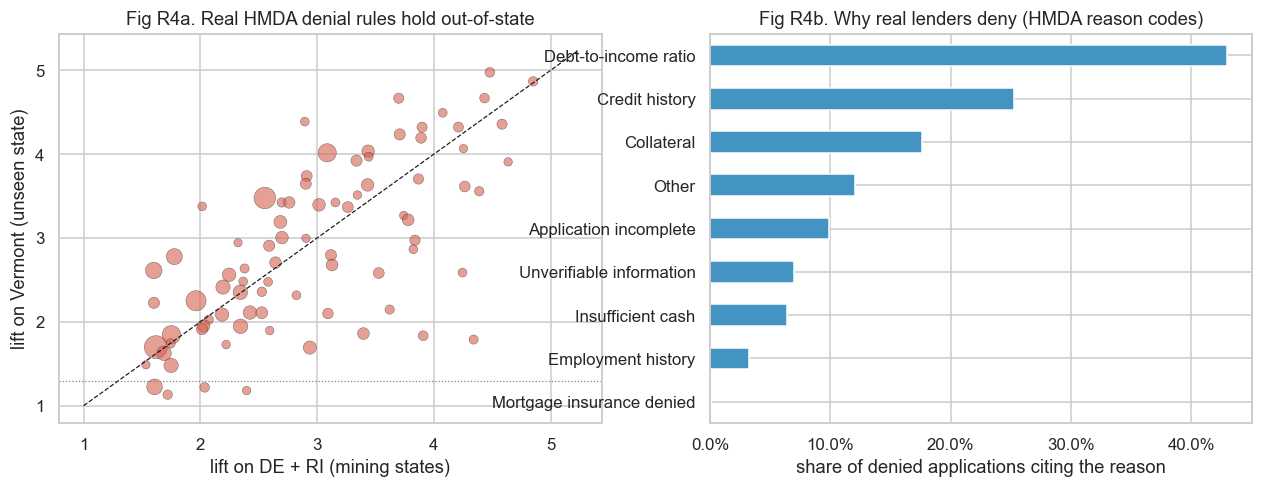

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].scatter(final['lift'], final['test_lift'], s=20 + 2000 * final['support'], alpha=.6, color='#d6604d', edgecolor='k', lw=.3)
lim = [1, max(final['lift'].max(), final['test_lift'].max()) * 1.05]
ax[0].plot(lim, lim, 'k--', lw=.8); ax[0].axhline(1.3, color='grey', ls=':', lw=.8)
ax[0].set(xlabel='lift on DE + RI (mining states)', ylabel='lift on Vermont (unseen state)', title='Fig R4a. Real HMDA denial rules hold out-of-state')
reasons = {1: 'Debt-to-income ratio', 2: 'Employment history', 3: 'Credit history', 4: 'Collateral', 5: 'Insufficient cash',
           6: 'Unverifiable information', 7: 'Application incomplete', 8: 'Mortgage insurance denied', 9: 'Other'}
den = h0[h0['DENIED']]
rc = pd.concat([den[f'denial_reason-{k}'] for k in range(1, 5)]).dropna().astype(int)
rc = rc[rc.isin(reasons)].map(reasons).value_counts() / len(den)
rc.sort_values().plot.barh(ax=ax[1], color='#4393c3')
ax[1].set(xlabel='share of denied applications citing the reason', title='Fig R4b. Why real lenders deny (HMDA reason codes)')
ax[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.savefig(os.path.join(FIG, 'R4_hmda_rules_reasons.png')); plt.show()
RESULTS['hmda_denial_reasons'] = rc.round(4).to_dict()

### D2. Rule-count score on real loans (same idea as notebook 07 Part C4)
Score = number of the top-25 validated rules an application triggers, evaluated on Vermont only.

In [16]:
from sklearn.metrics import roc_auc_score
top = final.head(25)['antecedents'].tolist()
score_te = sum(te_b[list(a)].all(axis=1).astype(int) for a in top)
auc_rules = roc_auc_score(te_b['DENIED'], score_te)
by_count = pd.DataFrame({'rules hit': np.minimum(score_te, 6), 'DENIED': te_b['DENIED']}).groupby('rules hit')['DENIED'].agg(['size', 'mean'])
by_count.columns = ['applications (VT)', 'denial rate']
RESULTS['hmda_rule_count_auc_VT'] = round(float(auc_rules), 4)
print(f'AUC of the rule-count score on Vermont: {auc_rules:.3f}')
by_count.round(3)

AUC of the rule-count score on Vermont: 0.707


,applications (VT),denial rate
rules hit,,
0,7999,0.101
1,373,0.373
2,403,0.558
3,117,0.556
4,145,0.614
5,140,0.671
6,171,0.801


### D3. Fairness check — do denial gaps by race and sex remain after the risk flags?
Raw gaps alone prove nothing (groups differ in DTI, LTV, income). A logistic regression of DENIED on the same 16 flags,
**plus** group indicators, estimates the gap that the flags do not explain. HMDA does not publish credit scores, so a remaining
gap is a signal for review — not proof of discrimination (Bartlett et al. 2022 make the same caveat).

In [17]:
fair = h0[['derived_race', 'derived_sex']].copy()
fair['DENIED'] = h0['DENIED'].astype(int)
raw_gap = pd.concat({'by race': fair.groupby('derived_race')['DENIED'].agg(['size', 'mean']),
                     'by sex': fair.groupby('derived_sex')['DENIED'].agg(['size', 'mean'])})
raw_gap = raw_gap[raw_gap['size'] >= 500].rename(columns={'size': 'applications', 'mean': 'denial rate'})
Xf = items.drop(columns='DENIED').astype(int)
Xf['black'] = (h0['derived_race'] == 'Black or African American').astype(int)
Xf['asian'] = (h0['derived_race'] == 'Asian').astype(int)
Xf['race_na'] = (h0['derived_race'] == 'Race Not Available').astype(int)
Xf['female'] = (h0['derived_sex'] == 'Female').astype(int)
Xf['state_RI'] = (h0['state_code'] == 'RI').astype(int); Xf['state_VT'] = (h0['state_code'] == 'VT').astype(int)
lg = sm.Logit(fair['DENIED'], sm.add_constant(Xf)).fit(disp=False)
gaps = pd.DataFrame({'adjusted odds ratio': np.exp(lg.params[['black', 'asian', 'race_na', 'female']]),
                     'p-value': lg.pvalues[['black', 'asian', 'race_na', 'female']]}).round(4)
RESULTS['hmda_fairness_adjusted_or'] = gaps.to_dict(orient='index')
display(raw_gap.round(3))
gaps

applications  denial rate
by race Asian                              1722        0.178
        Black or African American          5157        0.289
        Joint                               977        0.150
        Race Not Available                 8815        0.222
        White                             31731        0.164
by sex  Female                            12017        0.222
        Joint                             17448        0.137
        Male                              14600        0.222
        Sex Not Available                  4734        0.201

,adjusted odds ratio,p-value
black,1.7411,0.000
asian,1.7702,0.000
race_na,1.5450,0.000
female,1.0074,0.813


## Part E — What real borrowers complain about (CFPB, payday / title / personal loans)

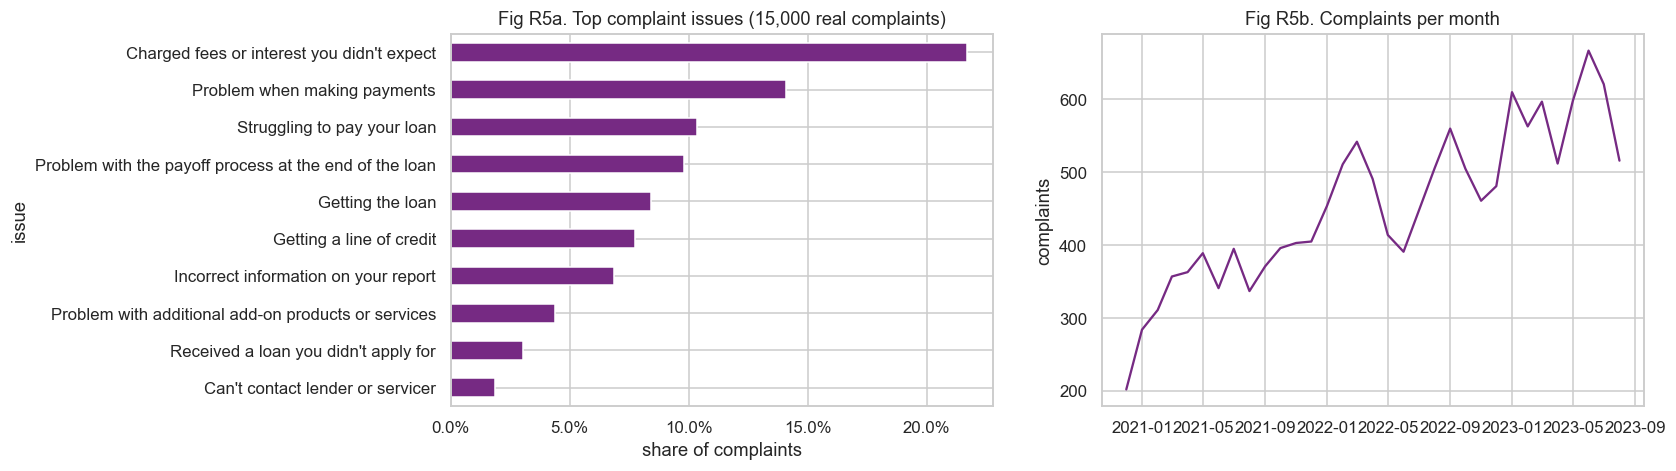

company responses:
company_response
Closed with explanation            0.895
Closed with monetary relief        0.050
Closed with non-monetary relief    0.050
Untimely response                  0.005


In [18]:
issue = cf['issue'].value_counts(normalize=True).head(10)
resp = cf['company_response'].value_counts(normalize=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
issue.sort_values().plot.barh(ax=ax[0], color='#762a83')
ax[0].set(title=f'Fig R5a. Top complaint issues ({len(cf):,} real complaints)', xlabel='share of complaints')
ax[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
monthly = cf.set_index('date_received').resample('MS').size()
ax[1].plot(monthly.index, monthly.values, color='#762a83'); ax[1].set(title='Fig R5b. Complaints per month', ylabel='complaints')
plt.savefig(os.path.join(FIG, 'R5_cfpb_issues.png')); plt.show()
RESULTS['cfpb_top_issues'] = issue.round(4).to_dict()
RESULTS['cfpb_relief_share'] = round(float(resp.filter(like='relief').sum()), 4)
RESULTS['cfpb_period'] = f"{cf.date_received.min().date()} to {cf.date_received.max().date()}"
print('company responses:'); print(resp.round(3).to_string())

## Part F — Synthetic-vs-real fidelity scorecard
What the real data **confirms**, what it **contradicts**, and what we change because of it.

In [19]:
pm = pd.read_csv(os.path.join(ROOT, 'data', 'portfolio', 'portfolio_monthly.csv'), parse_dates=['date'])
sim_annual = pm.set_index('date')['default_rate'].resample('YS').mean() * 100
real_annual = npl['npl_ratio_pct'].resample('YS').mean()
both = pd.concat({'simulated monthly default rate %': sim_annual, 'real India NPL ratio %': real_annual}, axis=1).dropna()
trend_corr = both.corr().iloc[0, 1]
covid_sim = sim_annual.loc['2020'].iloc[0] / sim_annual.loc['2019'].iloc[0]
covid_real = real_annual.loc['2020'].iloc[0] / real_annual.loc['2019'].iloc[0]
syn_lti_lift = 1.123     # LARGE_LOAN_VS_INCOME single-flag lift, notebook 07 Part A3
real_dti_lift = float(single.loc['DTI_50_PLUS', 'lift'])
score = pd.DataFrame([
    ['Macro direction: unemployment ↑ ⇒ defaults ↑, GDP ↑ ⇒ defaults ↓', 'yes (nb 06)', f"panel β: Δunemp {fe.params['d_unemp']:+.3f}, GDP {fe.params['gdp_growth']:+.3f} ({NC} countries)", 'CONFIRMED'],
    ['Default level falls 2019 → 2024 as the economy recovers', f"{both.iloc[0,0]:.2f}% → {both.iloc[-1,0]:.2f}%", f"{both.iloc[0,1]:.1f}% → {both.iloc[-1,1]:.1f}% (corr {trend_corr:.2f})", 'CONFIRMED'],
    ['COVID 2020 default spike', f'×{covid_sim:.1f} (2020 vs 2019)', f'×{covid_real:.2f} — moratorium & standstill hid it', 'CONTRADICTED → add forbearance regime'],
    ['Debt burden as a risk driver', f'loan-to-income flag lift {syn_lti_lift:.2f}', f'DTI ≥ 50% flag lift {real_dti_lift:.2f} (HMDA denials)', 'UNDER-WEIGHTED → recalibrate generator'],
    ['Multi-flag rules beat single flags & generalise out-of-sample', '93 rules, 100% hold on test', f"{RESULTS['hmda_rules']['final']} rules, {RESULTS['hmda_rules']['share_hold_out_of_state']:.0%} hold in an unseen state", 'CONFIRMED'],
], columns=['claim', 'synthetic project data', 'real data', 'verdict'])
RESULTS['fidelity_scorecard'] = score.to_dict(orient='records')
RESULTS['trend_corr_sim_vs_real'] = round(float(trend_corr), 3)
display(both.round(2))
score

,simulated monthly default rate %,real India NPL ratio %
2019-01-01,0.82,9.03
2020-01-01,1.89,8.06
2021-01-01,0.60,7.39
2022-01-01,0.40,5.28
2023-01-01,0.43,3.83
2024-01-01,0.32,2.72


,claim,synthetic project data,real data,verdict
0,"Macro direction: unemployment ↑ ⇒ defaults ↑, ...",yes (nb 06),"panel β: Δunemp +0.280, GDP -0.111 (140 countr...",CONFIRMED
1,Default level falls 2019 → 2024 as the economy...,0.82% → 0.32%,9.0% → 2.7% (corr 0.64),CONFIRMED
2,COVID 2020 default spike,×2.3 (2020 vs 2019),×0.89 — moratorium & standstill hid it,CONTRADICTED → add forbearance regime
3,Debt burden as a risk driver,loan-to-income flag lift 1.12,DTI ≥ 50% flag lift 2.55 (HMDA denials),UNDER-WEIGHTED → recalibrate generator
4,Multi-flag rules beat single flags & generalis...,"93 rules, 100% hold on test","82 rules, 95% hold in an unseen state",CONFIRMED


In [20]:
with open(os.path.join(OUT, 'real_data_results.json'), 'w', encoding='utf-8') as f:
    json.dump(RESULTS, f, indent=2, default=str)
bt_india.assign(actual=np.exp(bt_india['y']), forecast=np.exp(bt_india['mu'])).to_csv(os.path.join(OUT, 'india_npl_rolling_forecasts.csv'))
bt_us.assign(actual=np.exp(bt_us['y']), forecast=np.exp(bt_us['mu'])).to_csv(os.path.join(OUT, 'us_delinquency_rolling_forecasts.csv'))
fc_df = pd.DataFrame(fc); fc_df['actual'] = actual; fc_df.to_csv(os.path.join(OUT, 'india_npl_test_forecasts.csv'))
print('saved:', sorted(os.listdir(OUT)))

saved: ['hmda_denial_rules.csv', 'india_npl_model_comparison.csv', 'india_npl_rolling_forecasts.csv', 'india_npl_test_forecasts.csv', 'real_data_results.json', 'us_delinquency_rolling_forecasts.csv']


## Part G — Findings
1. **Method 1 works on real Indian default data — once the regulatory regime is modelled.** On the IMF series for Indian banks, BIC (on training data only) picks a SARIMAX with three regime ramps (AQR recognition, IBC clean-up, COVID standstill); on 14 unseen quarters it beats naive, drift, ETS and ARIMA (table B1). Macro drivers add little *after* the regimes: in India's real credit cycle, **recognition rules moved reported NPLs more than the economy did**. A lender's forecast has to track RBI's classification regime, not only GDP.
2. **Conformal intervals are more honest than model intervals.** In the rolling backtests (B2, B3) the adaptive conformal band stays close to its nominal coverage through the 2008 crisis and COVID, whereas the Gaussian band's coverage depends on the model being right. We therefore report ACI bands in the dashboard.
3. **The simulation's macro mechanism is real, not circular.** Across ~150 countries, NPLs rise when unemployment rises and fall when GDP grows (Part C) — the same signs that notebook 06 recovered from the simulated book.
4. **Method 2 generalises on real loans.** Apriori on 39k real HMDA applications finds denial rules that keep their lift in a state they were not mined on (Part D); debt-to-income ≥ 43–50% is the dominant real driver.
5. **Where synthetic data was wrong, and the fix:** (a) no forbearance regime — real COVID defaults were deferred, not spiked; (b) debt burden is under-weighted in the generator. Both are written into the Review 3 roadmap.